# ShopStream at Scale — Distributed Batch Analytics with PySpark

**Как запускать:** `Run All` в VS Code, или из терминала `python run_a2.py --scale medium --seed <ID4>`.
Все таблицы и графики сохраняются в папку `results/`.

Части: **A** ингест и хранение · **B** качество данных · **C** аналитика · **D** joins и skew · **E** бенчмарки · **F** отчёт

## 0. Параметры и данные

In [1]:
import os, sys, subprocess

# scale и seed можно передать снаружи (это делает run_a2.py); иначе берутся значения по умолчанию
SCALE = os.environ.get("A2_SCALE", "small")        # разработка: small, финальные цифры: medium
SEED  = int(os.environ.get("A2_SEED", "5820"))     # <-- ЗАМЕНИ 1234 на последние 4 цифры студенческого

DATA    = f"data/shopstream_{SCALE}_{SEED}"
EVENTS  = f"{DATA}/events"
RESULTS = "results"
os.makedirs(RESULTS, exist_ok=True)
print(SCALE, SEED, DATA)

small 5820 data/shopstream_small_5820


In [2]:
# Генерируем данные, только если их ещё нет (тот же seed -> точно такие же данные)
if not os.path.exists(f"{DATA}/_meta.json"):
    subprocess.run([sys.executable, "shopstream_gen.py", "--out", DATA,
                    "--scale", SCALE, "--seed", str(SEED)], check=True)
print(open(f"{DATA}/_meta.json").read())

{
  "scale": "small",
  "seed": 5820,
  "n_users": 8000,
  "n_products": 1500,
  "n_days": 45,
  "n_events_written": 550883,
  "n_files": 180,
  "start_date": "2026-07-01"
}


In [3]:
import os, sys, shutil
print("Python:", sys.executable)
print("JAVA_HOME:", os.environ.get("JAVA_HOME"))
print("java в PATH:", shutil.which("java"))
print("java в conda-окружении:", os.path.exists(os.path.join(sys.prefix, "Library", "bin", "java.exe")))

Python: c:\Users\Dana\miniconda3\envs\shopstream\python.exe
JAVA_HOME: None
java в PATH: None
java в conda-окружении: True


## 1. Spark и окружение

In [4]:
import time, statistics, platform, json
import pandas as pd
import psutil

# Spark должен использовать тот же Python, что и ноутбук
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

if platform.system() == "Windows":
    # Java из conda-окружения: VS Code не активирует conda, поэтому указываем путь сами
    conda_java = os.path.join(sys.prefix, "Library")
    if os.path.exists(os.path.join(conda_java, "bin", "java.exe")):
        os.environ["JAVA_HOME"] = conda_java
        os.environ["PATH"] = os.path.join(conda_java, "bin") + ";" + os.environ["PATH"]
    # winutils для записи файлов
    os.environ["HADOOP_HOME"] = r"C:\hadoop"
    os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]

print("JAVA_HOME =", os.environ.get("JAVA_HOME"))

from pyspark.sql import SparkSession, functions as F, types as T

RAM_GB = psutil.virtual_memory().total / 1e9

spark = (SparkSession.builder
         .master("local[*]")
         .appName("ShopStream-A2")
         .config("spark.driver.memory", f"{max(2, int(RAM_GB * 0.5))}g")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.local.dir", os.path.abspath("spark_tmp"))
         .config("spark.ui.port", "4040")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")

print("Spark", spark.version, "| ядер:", spark.sparkContext.defaultParallelism)
print("Spark UI: http://localhost:4040")

JAVA_HOME = c:\Users\Dana\miniconda3\envs\shopstream\Library
Spark 3.5.3 | ядер: 16
Spark UI: http://localhost:4040


In [5]:
# Окружение — обязательно для отчёта (все замеры без него не засчитываются)
java_out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
ENV = {
    "OS": platform.platform(),
    "CPU": platform.processor(),
    "CPU cores (logical)": os.cpu_count(),
    "RAM_GB": round(RAM_GB, 1),
    "Python": sys.version.split()[0],
    "Java": next(l for l in java_out.splitlines() if "version" in l).strip(),
    "Spark": spark.version,
    "scale": SCALE, "seed": SEED,
}
json.dump(ENV, open(f"{RESULTS}/environment.json", "w"), indent=2)
ENV

{'OS': 'Windows-10-10.0.26200-SP0',
 'CPU': 'AMD64 Family 26 Model 96 Stepping 0, AuthenticAMD',
 'CPU cores (logical)': 16,
 'RAM_GB': 16.2,
 'Python': '3.11.17',
 'Java': 'openjdk version "17.0.18" 2026-01-20 LTS',
 'Spark': '3.5.3',
 'scale': 'small',
 'seed': 5820}

## 2. Инструменты для замеров
- `bench` — медиана из 3 запусков + 1 прогревочный (не учитывается).
- `force` — заставляет Spark посчитать весь DataFrame, но ничего не сохранять (`noop`).
  `.show()` считает только 20 строк, `.collect()` меряет перенос данных в драйвер — оба врут.

In [6]:
def bench(fn, runs=3, warmup=True):
    """Запускает fn() runs раз. Возвращает (медиана, список времён) в секундах."""
    if warmup:
        fn()                           # прогрев: кэш диска ОС, загрузка классов Java
    times = []
    for _ in range(runs):
        spark.catalog.clearCache()     # чистим кэш Spark между запусками
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return statistics.median(times), times


def force(df):
    """Полностью вычисляет df, ничего не записывая на диск."""
    df.write.format("noop").mode("overwrite").save()

# Part A — Ingestion and storage layout
## A1. Чтение схемы: автоопределение vs явная схема

In [7]:
# Первый взгляд на сырые события
peek = spark.read.json(EVENTS)
peek.printSchema()
peek.show(5, truncate=False)

root
 |-- app_version: string (nullable = true)
 |-- device: string (nullable = true)
 |-- event_id: string (nullable = true)
 |-- event_ts: string (nullable = true)
 |-- event_type: string (nullable = true)
 |-- ingest_ts: string (nullable = true)
 |-- price: double (nullable = true)
 |-- product_id: string (nullable = true)
 |-- quantity: long (nullable = true)
 |-- session_id: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- date: date (nullable = true)

+-----------+-------+------------------+--------------------+----------------+--------------------+------+----------+--------+-----------+--------+----------+
|app_version|device |event_id          |event_ts            |event_type      |ingest_ts           |price |product_id|quantity|session_id |user_id |date      |
+-----------+-------+------------------+--------------------+----------------+--------------------+------+----------+--------+-----------+--------+----------+
|5.2.0      |desktop|e_78b7a164cead5004|2

Колонка `date` — не из JSON, а из названия папки `date=...`.
Это дата **прихода события на сервер** (ingest), а не дата события. Пригодится в Part B.

In [8]:
event_schema = T.StructType([
    T.StructField("event_id",    T.StringType()),
    T.StructField("user_id",     T.StringType()),
    T.StructField("session_id",  T.StringType()),
    T.StructField("product_id",  T.StringType()),
    T.StructField("event_type",  T.StringType()),
    T.StructField("event_ts",    T.StringType()),   # строкой: бывает мусор, парсим сами в Part B
    T.StructField("ingest_ts",   T.StringType()),
    T.StructField("price",       T.DoubleType()),
    T.StructField("quantity",    T.LongType()),
    T.StructField("device",      T.StringType()),
    T.StructField("app_version", T.StringType()),
])

In [9]:
def only_read_inferred():  return spark.read.json(EVENTS)
def only_read_explicit():  return spark.read.schema(event_schema).json(EVENTS)
def read_count_inferred(): return spark.read.json(EVENTS).count()
def read_count_explicit(): return spark.read.schema(event_schema).json(EVENTS).count()

rows = []
for name, fn in [("inferred: read only",    only_read_inferred),
                 ("explicit: read only",    only_read_explicit),
                 ("inferred: read + count", read_count_inferred),
                 ("explicit: read + count", read_count_explicit)]:
    med, ts = bench(fn)
    rows.append({"variant": name, "median_s": round(med, 3), "runs_s": [round(t, 3) for t in ts]})

N_RAW = read_count_explicit()
assert N_RAW == read_count_inferred(), "количество строк должно совпадать"

a1 = pd.DataFrame(rows)
a1.to_csv(f"{RESULTS}/A1_schema_read_times.csv", index=False)
print("n_raw =", N_RAW)
a1

n_raw = 550883


,variant,median_s,runs_s
0,inferred: read only,0.578,"[1.347, 0.556, 0.578]"
1,explicit: read only,0.118,"[0.108, 0.118, 0.121]"
2,inferred: read + count,0.923,"[0.95, 0.923, 0.831]"
3,explicit: read + count,0.321,"[0.321, 0.318, 0.322]"


# Part B — Чистка данных
## B1. Загрузка

In [10]:
# ===== Part B. Загрузка сырых данных и справочников =====
from pyspark.sql import Window

# Новый строгий парсер дат: всё, что не подходит под формат, становится NULL (а не ошибкой)
spark.conf.set("spark.sql.legacy.timeParserPolicy", "CORRECTED")

TS_FMT = "yyyy-MM-dd'T'HH:mm:ss'Z'"            # формат вида 2026-07-01T07:00:00Z
VALID_TYPES = ["view", "add_to_cart", "remove_from_cart", "purchase"]
LAKE = f"{DATA}/lake"                           # сюда пишем таблицы (папка data/ не попадает в git)

raw = spark.read.schema(event_schema).json(EVENTS).drop("date")   # date = папка прихода, не нужна
products = spark.read.csv(f"{DATA}/products.csv", header=True, inferSchema=True)
users    = spark.read.csv(f"{DATA}/users.csv",    header=True, inferSchema=True)

N_RAW = raw.count()
print("сырых событий:", N_RAW, "| товаров:", products.count(), "| пользователей:", users.count())

сырых событий: 550883 | товаров: 1500 | пользователей: 8001


## B2. Дубликаты

In [11]:
# ===== R6. Дубликаты: из копий одного event_id оставляем ту, что пришла раньше всех =====
# Window = "окно": группа строк с одинаковым event_id, отсортированная по времени прихода.
# row_number() нумерует копии внутри группы: 1 = самая ранняя.
w_first = Window.partitionBy("event_id").orderBy(F.col("ingest_ts_parsed").asc_nulls_last())

deduped = (raw
           .withColumn("ingest_ts_parsed", F.to_timestamp("ingest_ts", TS_FMT))
           .withColumn("_copy_no", F.row_number().over(w_first))
           .filter(F.col("_copy_no") == 1)
           .drop("_copy_no")
           .cache())                            # используем много раз — держим в памяти

N_DEDUP = deduped.count()
N_DUP_REMOVED = N_RAW - N_DEDUP
print(f"удалено дубликатов: {N_DUP_REMOVED} ({N_DUP_REMOVED / N_RAW:.2%})")

удалено дубликатов: 3286 (0.60%)


In [12]:
# Пример дубликата: одинаковый event_id, одинаковое событие, но разное время прихода
one_dup = raw.groupBy("event_id").count().filter("count > 1").limit(1)
raw.join(one_dup, "event_id").select("event_id", "user_id", "event_type", "event_ts", "ingest_ts").show(truncate=False)

+------------------+--------+----------+--------------------+--------------------+
|event_id          |user_id |event_type|event_ts            |ingest_ts           |
+------------------+--------+----------+--------------------+--------------------+
|e_421262008149c6f6|u_006991|view      |2026-07-19T16:13:43Z|2026-07-19T16:13:43Z|
|e_421262008149c6f6|u_006991|view      |2026-07-19T16:13:43Z|2026-07-19T16:20:41Z|
+------------------+--------+----------+--------------------+--------------------+



## B3. Правила R1-R5

In [13]:
# ===== R1–R5: проверяем каждую строку, все причины собираем в массив dq_reasons =====
catalog = products.select("product_id").withColumn("_in_catalog", F.lit(True))

checked = (deduped
           .withColumn("event_ts_parsed", F.to_timestamp("event_ts", TS_FMT))
           .withColumn("event_type_norm", F.lower(F.trim("event_type")))     # " VIEW " -> "view"
           .join(F.broadcast(catalog), on="product_id", how="left"))          # нет товара -> _in_catalog = NULL

rules = {
    "R1": F.col("user_id").isNull(),
    "R2": (F.col("event_ts_parsed").isNull()
           | (F.col("event_ts_parsed") < F.lit("2026-01-01").cast("timestamp"))
           | (F.col("event_ts_parsed") > F.col("ingest_ts_parsed"))),
    "R3": F.col("price").isNull() | (F.col("price") <= 0),
    "R4": F.col("event_type_norm").isNull() | ~F.col("event_type_norm").isin(VALID_TYPES),
    "R5": F.col("_in_catalog").isNull(),
}

# Для каждого правила: если нарушено — пишем его код, иначе NULL. Потом выкидываем NULL из массива.
reason_array = F.array(*[F.when(cond, F.lit(code)) for code, cond in rules.items()])
checked = checked.withColumn("dq_reasons", F.filter(reason_array, lambda x: x.isNotNull())).cache()

**Вывод для отчёта (дополнить своими цифрами):**
у JSON нет встроенной схемы, поэтому без неё Spark делает **лишний полный проход** по всем файлам,
чтобы угадать типы (видно по строке `inferred: read only` — время тратится ещё до `count()`).
С явной схемой проход один, а типы стабильны и не зависят от случайного мусора в данных.

In [14]:
# ===== Разделяем на silver и quarantine =====
quarantine = checked.filter(F.size("dq_reasons") > 0).select(*raw.columns, "dq_reasons")

silver_base = (checked.filter(F.size("dq_reasons") == 0)
               .select("event_id", "user_id", "session_id", "product_id",
                       F.col("event_type_norm").alias("event_type"),
                       F.col("event_ts_parsed").alias("event_ts"),
                       F.col("ingest_ts_parsed").alias("ingest_ts"),
                       "price", "quantity", "device", "app_version",
                       F.to_date("event_ts_parsed").alias("event_date")))   # дата СОБЫТИЯ, не прихода

N_QUAR = quarantine.count()
N_SILVER = silver_base.count()

# Обязательная сверка: ни одна строка не потерялась и не появилась из ниоткуда
assert N_RAW == N_SILVER + N_QUAR + N_DUP_REMOVED, "строки потерялись!"
print(f"raw {N_RAW} = silver {N_SILVER} + quarantine {N_QUAR} + duplicates {N_DUP_REMOVED}  ✓")

raw 550883 = silver 538071 + quarantine 9526 + duplicates 3286  ✓


In [15]:
# ===== dq_report: сколько строк нарушило каждое правило =====
rule_desc = {
    "R1": "user_id is NULL",
    "R2": "event_ts unparseable / before 2026-01-01 / after ingest_ts",
    "R3": "price <= 0 or NULL",
    "R4": "event_type invalid after trim + lower",
    "R5": "product_id not in products.csv",
}
counts = {r["rule"]: r["count"] for r in
          quarantine.select(F.explode("dq_reasons").alias("rule")).groupBy("rule").count().collect()}

rows = [{"rule": k, "definition": v, "rows": counts.get(k, 0)} for k, v in rule_desc.items()]
rows += [
    {"rule": "R6", "definition": "duplicate event_id (later copies removed)", "rows": N_DUP_REMOVED},
    {"rule": "quarantine", "definition": "rows failing >= 1 of R1-R5", "rows": N_QUAR},
    {"rule": "silver", "definition": "valid rows", "rows": N_SILVER},
]
dq_report = pd.DataFrame(rows)
dq_report["pct_of_raw"] = (100 * dq_report["rows"] / N_RAW).round(3)
dq_report.to_csv(f"{RESULTS}/B_dq_report.csv", index=False)

n_multi = quarantine.filter(F.size("dq_reasons") > 1).count()
print("строк с несколькими нарушениями сразу:", n_multi)
dq_report

строк с несколькими нарушениями сразу: 60


,rule,definition,rows,pct_of_raw
0,R1,user_id is NULL,4565,0.829
1,R2,event_ts unparseable / before 2026-01-01 / aft...,1135,0.206
2,R3,price <= 0 or NULL,1644,0.298
3,R4,event_type invalid after trim + lower,0,0.000
4,R5,product_id not in products.csv,2242,0.407
5,R6,duplicate event_id (later copies removed),3286,0.596
6,quarantine,rows failing >= 1 of R1-R5,9526,1.729
7,silver,valid rows,538071,97.674


In [16]:
# Сохраняем карантин (заодно проверяем, что запись на Windows работает)
quarantine.write.mode("overwrite").parquet(f"{LAKE}/quarantine_events")
quarantine.groupBy("dq_reasons").count().orderBy(F.desc("count")).show(truncate=False)

+----------+-----+
|dq_reasons|count|
+----------+-----+
|[R1]      |4521 |
|[R5]      |2212 |
|[R3]      |1618 |
|[R2]      |1115 |
|[R1, R5]  |16   |
|[R1, R2]  |14   |
|[R1, R3]  |14   |
|[R3, R5]  |10   |
|[R2, R5]  |4    |
|[R2, R3]  |2    |
+----------+-----+



In [17]:
# Сколько событий лежит в папке "не своего" дня (пришло после полуночи, а случилось накануне)
late = silver_base.filter(F.to_date("ingest_ts") != F.col("event_date")).count()
print(f"событий в папке другого дня: {late} ({late / N_SILVER:.2%})")

событий в папке другого дня: 5 (0.00%)


## B4. Поиска бота

In [18]:
# ===== Статистика по каждому пользователю =====
user_stats = (silver_base.groupBy("user_id").agg(
                  F.count("*").alias("n_events"),
                  F.countDistinct("event_date").alias("active_days"),
                  F.sum(F.when(F.col("event_type") != "view", 1).otherwise(0)).alias("n_cart_activity"))
              .withColumn("events_per_day", F.col("n_events") / F.col("active_days"))
              .cache())

# Пороги берём из самих данных: 99.9-й перцентиль (выше него только 0.1% пользователей)
p = user_stats.agg(
        F.percentile_approx("events_per_day", [0.5, 0.99, 0.999], 100000).alias("epd"),
        F.percentile_approx("n_events", 0.999, 100000).alias("n999")).first()
EPD_P50, EPD_P99, EPD_P999 = p["epd"]
N_P999 = p["n999"]
print(f"событий в день: медиана {EPD_P50:.1f}, p99 {EPD_P99:.1f}, p99.9 {EPD_P999:.1f} | событий всего p99.9: {N_P999}")

bot_rule = ((F.col("events_per_day") > EPD_P999)
            & (F.col("n_events") > N_P999)
            & (F.col("n_cart_activity") == 0))

bots = user_stats.filter(bot_rule)
bots.show()

событий в день: медиана 6.4, p99 15.0, p99.9 21.3 | событий всего p99.9: 708
+--------+--------+-----------+---------------+-----------------+
| user_id|n_events|active_days|n_cart_activity|   events_per_day|
+--------+--------+-----------+---------------+-----------------+
|u_000000|   20670|         45|              0|459.3333333333333|
+--------+--------+-----------+---------------+-----------------+



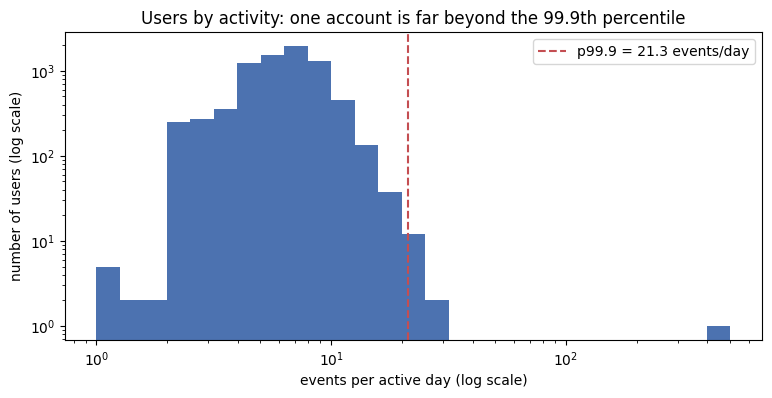

In [19]:
# ===== График распределения (считаем гистограмму в Spark, в pandas — только ~50 корзинок) =====
import matplotlib.pyplot as plt
import numpy as np

hist = (user_stats
        .withColumn("bin", F.floor(F.log10("events_per_day") * 10) / 10)   # корзинки шириной 0.1 по log10
        .groupBy("bin").count().orderBy("bin").toPandas())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(10 ** hist["bin"], hist["count"], width=10 ** (hist["bin"] + 0.1) - 10 ** hist["bin"],
       align="edge", color="#4C72B0")
ax.axvline(EPD_P999, color="#C44E52", linestyle="--", label=f"p99.9 = {EPD_P999:.1f} events/day")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("events per active day (log scale)")
ax.set_ylabel("number of users (log scale)")
ax.set_title("Users by activity: one account is far beyond the 99.9th percentile")
ax.legend()
plt.savefig(f"{RESULTS}/B_bot_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
# ===== Помечаем ботов (не удаляем!) и собираем итоговый silver =====
bot_flags = bots.select("user_id").withColumn("is_bot", F.lit(True))

silver = (silver_base
          .join(F.broadcast(bot_flags), on="user_id", how="left")
          .withColumn("is_bot", F.coalesce(F.col("is_bot"), F.lit(False)))
          .cache())

n_bot_users = bots.count()
n_bot_events = silver.filter("is_bot").count()
bot_summary = pd.DataFrame([{
    "rule": "events_per_day > p99.9 AND n_events > p99.9 AND no cart/purchase activity",
    "p999_events_per_day": round(EPD_P999, 2), "p999_n_events": N_P999,
    "bot_users": n_bot_users, "bot_events": n_bot_events,
    "pct_of_silver_events": round(100 * n_bot_events / N_SILVER, 2)}])
bot_summary.to_csv(f"{RESULTS}/B_bot_summary.csv", index=False)
bot_summary.T

,0
rule,events_per_day > p99.9 AND n_events > p99.9 AN...
p999_events_per_day,21.29
p999_n_events,708
bot_users,1
bot_events,20670
pct_of_silver_events,3.84


In [21]:
# Сколько event_type было "грязных", но исправилось нормализацией (а не попало в карантин)
n_fixed = deduped.filter(F.col("event_type") != F.lower(F.trim("event_type"))).count()
print("исправлено нормализацией event_type:", n_fixed)

исправлено нормализацией event_type: 5348


# Part A. Как сохранить Silver на диск

## A2.1. Подготовка

In [23]:
# ===== Part A2. Silver на диск =====
# Один раз сохраняем silver "как есть", без раскладки по папкам.
# Это (1) unpartitioned-версия для A3 и (2) общий источник, чтобы честно сравнить три способа записи.
SILVER_FLAT = f"{LAKE}/silver_flat"
silver.write.mode("overwrite").parquet(SILVER_FLAT)
silver_src = spark.read.parquet(SILVER_FLAT)

# Освобождаем память от промежуточных таблиц
for df_ in (deduped, checked, silver_base, user_stats, silver):
    df_.unpersist()
print("строк:", silver_src.count(), "| партиций при чтении:", silver_src.rdd.getNumPartitions())

строк: 538071 | партиций при чтении: 16


In [24]:
def file_stats(path):
    """Считает parquet-файлы в папке (со всеми подпапками) и их размеры."""
    sizes, days = [], set()
    for root, _, files in os.walk(path):
        for f in files:
            if f.endswith(".parquet"):
                sizes.append(os.path.getsize(os.path.join(root, f)))
                days.add(os.path.basename(root))
    s = pd.Series(sizes) / 1024                                   # в КБ
    return {"n_files": len(sizes), "n_day_folders": len(days),
            "files_per_day": round(len(sizes) / max(1, len(days)), 1),
            "min_KB": round(s.min(), 1), "median_KB": round(s.median(), 1),
            "max_KB": round(s.max(), 1), "total_MB": round(s.sum() / 1024, 2)}

## A2.2. Своя стратегия 

Идея: самый большой день получает 4 файла, остальные дни — пропорционально своему размеру, но минимум 1. Тогда все файлы получаются примерно одинаковыми. Внутри дня строки делятся на «корзинки» по хэшу event_id, как раскладка карточек по последней цифре номера.

In [25]:
# Сколько строк в каждом дне и сколько файлов ему дать (1..4)
day_rows = silver_src.groupBy("event_date").count()
max_day = day_rows.agg(F.max("count")).first()[0]

day_files = (day_rows
             .withColumn("k", F.ceil(4 * F.col("count") / F.lit(max_day)).cast("int"))
             .withColumn("offset", F.sum("k").over(Window.orderBy("event_date")) - F.col("k")))
P = day_files.agg(F.sum("k")).first()[0]          # всего файлов будет примерно P
print("всего целевых файлов P =", P)

# Каждой строке: номер корзинки внутри дня (0..k-1) и уникальный номер файла part_id (0..P-1)
with_bucket = (silver_src
               .join(F.broadcast(day_files.select("event_date", "k", "offset")), "event_date")
               .withColumn("bucket", F.pmod(F.xxhash64("event_id"), F.col("k")))
               .withColumn("part_id", F.col("offset") + F.col("bucket")))

всего целевых файлов P = 149


## A2.3 Сравнения трех способов

In [26]:
PATHS = {
    "i_direct":       f"{LAKE}/silver_i_direct",
    "ii_repartition": f"{LAKE}/silver_ii_repartition",
    "iii_balanced":   f"{LAKE}/silver_iii_balanced",
}

def write_i():    # как есть: каждая задача пишет свой файл в КАЖДЫЙ день, который ей попался
    silver_src.write.mode("overwrite").partitionBy("event_date").parquet(PATHS["i_direct"])

def write_ii():   # все строки одного дня -> в одну задачу -> 1 файл на день
    (silver_src.repartition("event_date")
     .write.mode("overwrite").partitionBy("event_date").parquet(PATHS["ii_repartition"]))

def write_iii():  # каждая (день, корзинка) -> своя задача -> 1-4 файла на день примерно равного размера
    (with_bucket.repartitionByRange(P, "part_id")
     .drop("k", "offset", "bucket", "part_id")
     .write.mode("overwrite").partitionBy("event_date").parquet(PATHS["iii_balanced"]))

rows = []
for name, fn in [("i_direct", write_i), ("ii_repartition", write_ii), ("iii_balanced", write_iii)]:
    med, ts = bench(fn)
    rows.append({"strategy": name, "write_median_s": round(med, 2),
                 "runs_s": [round(t, 2) for t in ts], **file_stats(PATHS[name])})

a2 = pd.DataFrame(rows)
a2.to_csv(f"{RESULTS}/A2_write_strategies.csv", index=False)
a2

,strategy,write_median_s,runs_s,n_files,n_day_folders,files_per_day,min_KB,median_KB,max_KB,total_MB
0,i_direct,4.53,"[4.68, 4.53, 4.4]",720,45,16.0,16.3,42.0,62.1,30.02
1,ii_repartition,2.01,"[2.01, 1.75, 2.78]",45,45,1.0,431.1,501.1,693.9,23.15
2,iii_balanced,9.26,"[10.61, 9.26, 6.53]",148,45,3.3,147.2,178.9,286.9,25.72


# Part A3 — partition pruning и pushdown

In [27]:
# ===== Part A3. "Выручка electronics-покупок с 2026-08-10 по 2026-08-16" на трёх видах хранения =====
import io, contextlib

D1, D2 = F.to_date(F.lit("2026-08-10")), F.to_date(F.lit("2026-08-16"))
electronics = products.filter(F.col("category") == "electronics").select("product_id")

def q_raw():
    df = spark.read.schema(event_schema).json(EVENTS)
    return (df.filter(F.lower(F.trim("event_type")) == "purchase")
              .withColumn("event_date", F.to_date(F.to_timestamp("event_ts", TS_FMT)))
              .filter(F.col("event_date").between(D1, D2))
              .join(F.broadcast(electronics), "product_id")
              .agg(F.round(F.sum(F.col("price") * F.col("quantity")), 2).alias("revenue")))

def q_parquet(path):
    df = spark.read.parquet(path)
    return (df.filter((F.col("event_type") == "purchase") & F.col("event_date").between(D1, D2))
              .join(F.broadcast(electronics), "product_id")
              .agg(F.round(F.sum(F.col("price") * F.col("quantity")), 2).alias("revenue")))

def plan_text(df):
    """Захватывает текст df.explain('formatted') в строку."""
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df.explain(mode="formatted")
    return buf.getvalue()

variants = {
    "raw_json":            q_raw,
    "parquet_unpartitioned": lambda: q_parquet(SILVER_FLAT),
    "parquet_partitioned":   lambda: q_parquet(PATHS["iii_balanced"]),
}

rows, plan_lines = [], []
for name, make_q in variants.items():
    med, ts = bench(lambda: force(make_q()))
    revenue = make_q().first()["revenue"]
    plan = plan_text(make_q())
    open(f"{RESULTS}/A3_plan_{name}.txt", "w").write(plan)          # полный план — в приложение отчёта
    for line in plan.splitlines():
        if any(k in line for k in ("PartitionFilters", "PushedFilters", "ReadSchema", "Location")):
            plan_lines.append({"variant": name, "plan_line": line.strip()[:300]})
    rows.append({"variant": name, "median_s": round(med, 3),
                 "runs_s": [round(t, 3) for t in ts], "revenue": revenue})

a3 = pd.DataFrame(rows)
a3.to_csv(f"{RESULTS}/A3_pruning_times.csv", index=False)
pd.DataFrame(plan_lines).to_csv(f"{RESULTS}/A3_plan_key_lines.csv", index=False)

assert a3.loc[1, "revenue"] == a3.loc[2, "revenue"], "две Parquet-версии должны давать одну выручку"
display(a3)
pd.set_option("display.max_colwidth", 300)
pd.DataFrame(plan_lines)

,variant,median_s,runs_s,revenue
0,raw_json,0.732,"[0.601, 0.86, 0.732]",61804.06
1,parquet_unpartitioned,0.369,"[0.432, 0.368, 0.369]",61220.40
2,parquet_partitioned,0.427,"[0.427, 0.389, 0.454]",61220.40


,variant,plan_line
0,raw_json,Location: InMemoryFileIndex [file:/c:/Users/Dana/Desktop/shopstream-spark/data/shopstream_small_5820/events]
1,raw_json,PushedFilters: [IsNotNull(product_id)]
2,raw_json,"ReadSchema: struct<product_id:string,event_type:string,event_ts:string,price:double,quantity:bigint>"
3,raw_json,Location: InMemoryFileIndex [file:/c:/Users/Dana/Desktop/shopstream-spark/data/shopstream_small_5820/products.csv]
4,raw_json,"PushedFilters: [IsNotNull(category), EqualTo(category,electronics), IsNotNull(product_id)]"
5,raw_json,"ReadSchema: struct<product_id:string,category:string>"
6,parquet_unpartitioned,Location: InMemoryFileIndex [file:/c:/Users/Dana/Desktop/shopstream-spark/data/shopstream_small_5820/lake/silver_flat]
7,parquet_unpartitioned,"PushedFilters: [IsNotNull(event_type), IsNotNull(event_date), EqualTo(event_type,purchase), GreaterThanOrEqual(event_date,2026-08-10), LessThanOrEqual(event_date,2026-08-16), IsNotNull(product_id)]"
8,parquet_unpartitioned,"ReadSchema: struct<product_id:string,event_type:string,price:double,quantity:bigint,event_date:date>"
9,parquet_unpartitioned,Location: InMemoryFileIndex [file:/c:/Users/Dana/Desktop/shopstream-spark/data/shopstream_small_5820/products.csv]
